In [1]:
from pathlib import Path
import math

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Relative paths assume that the notebook is run from the project directory.
FILES = {
    'inflow': Path('data/source_newcomer_inflow_growth.csv'),
    'transient': Path('data/source_transient_by_cohort.csv'),
    'km': Path('data/source_pooled_km_5year.csv'),
    'novelty_hist': Path('data/keyword_novelty_histogram_bins.csv'),
    'novelty_summary': Path('data/keyword_novelty_summary.csv'),
    'country': Path('data/source_country_ai_six_disciplines.csv'),
    'citation': Path('data/source_citation_gini_ai_six_disciplines.csv'),
}

COLORS = {'AI': '#D95F5F', 'Traditional': '#4C78A8'}
GROUPS = ['AI', 'Traditional']

mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 7.2,
    'axes.labelsize': 8.2,
    'xtick.labelsize': 7.0,
    'ytick.labelsize': 7.0,
    'axes.linewidth': 0.8,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'xtick.major.size': 3.2,
    'ytick.major.size': 3.2,
    'legend.fontsize': 6.8,
    'legend.frameon': False,
    'svg.fonttype': 'none',
    'pdf.fonttype': 42,
})


In [2]:
def style_axis(ax, grid='y', boxed=True):
    ax.set_axisbelow(True)
    if grid:
        ax.grid(axis=grid, color='#E1E1E1', lw=0.55, zorder=0)
    for side in ['left', 'bottom', 'right', 'top']:
        ax.spines[side].set_visible(boxed or side in ['left', 'bottom'])
        ax.spines[side].set_linewidth(0.8)


def panel_label(ax, label, x=-0.145):
    ax.text(x, 1.0, label, transform=ax.transAxes, ha='right', va='top',
            fontsize=11.5, fontweight='bold', clip_on=False)


def greenwood_ci(frame):
    frame = frame.sort_values('year').copy()
    n = frame.at_risk.to_numpy(dtype=float)
    d = frame.events.to_numpy(dtype=float)
    s = frame.survival.to_numpy(dtype=float)
    increments = np.divide(d, n * (n - d), out=np.zeros_like(d),
                           where=(n > d) & (n > 0))
    greenwood = np.cumsum(increments)
    lower = np.ones_like(s)
    upper = np.ones_like(s)
    valid = (s > 0) & (s < 1) & (greenwood > 0)
    theta = np.log(-np.log(s[valid]))
    se_theta = np.sqrt(greenwood[valid]) / np.abs(np.log(s[valid]))
    lower[valid] = np.exp(-np.exp(theta + 1.96 * se_theta))
    upper[valid] = np.exp(-np.exp(theta - 1.96 * se_theta))
    return lower, upper


def horizontal_field_boxplot(ax, data, value_col, xlabel, seed, x_jitter=0.003):
    traditional = [d for d in data.discipline.unique() if d != 'AI']
    medians = data[data.discipline.isin(traditional)].groupby('discipline')[value_col].median()
    order = medians.sort_values().index.tolist() + ['AI']
    positions = np.arange(len(order))
    values = [data.loc[data.discipline.eq(d), value_col].dropna().to_numpy()
              for d in order]

    box = ax.boxplot(
        values, positions=positions, vert=False, widths=0.55,
        patch_artist=True, showfliers=False, whis=1.5,
        medianprops={'lw': 1.6}, whiskerprops={'lw': 0.85},
        capprops={'lw': 0.85}
    )

    artists = zip(box['boxes'], box['medians'],
                  box['whiskers'][::2], box['whiskers'][1::2],
                  box['caps'][::2], box['caps'][1::2])
    for i, (patch, median, whisker1, whisker2, cap1, cap2) in enumerate(artists):
        color = COLORS['AI'] if order[i] == 'AI' else COLORS['Traditional']
        patch.set(facecolor=color, edgecolor=color, alpha=0.18, linewidth=1.0)
        median.set(color=color)
        for artist in [whisker1, whisker2, cap1, cap2]:
            artist.set(color=color)

    rng = np.random.default_rng(seed)
    value_range = data[value_col].max() - data[value_col].min()
    for i, (discipline, vals) in enumerate(zip(order, values)):
        color = COLORS['AI'] if discipline == 'AI' else COLORS['Traditional']
        y = i + rng.uniform(-0.18, 0.18, len(vals))
        x = vals + rng.uniform(-x_jitter, x_jitter, len(vals)) * value_range
        ax.scatter(x, y, s=18, facecolor=color, edgecolor='white',
                   linewidth=0.35, alpha=0.50, zorder=3)

    ax.set_yticks(positions, order)
    ax.set_xlabel(xlabel)
    ax.margins(x=0.06, y=0.08)
    style_axis(ax, grid='x', boxed=False)


## Figure 1: researcher entry and novelty


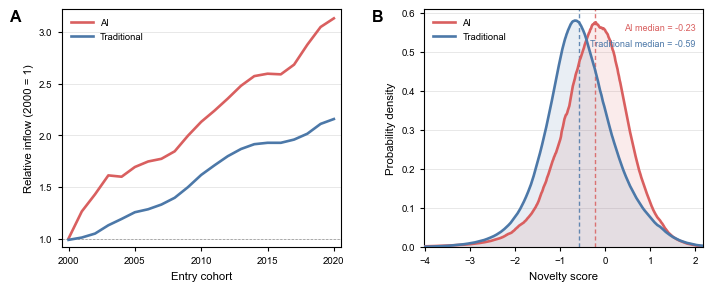

In [3]:
inflow = pd.read_csv(FILES['inflow']).query('2000 <= cohort <= 2020').copy()
inflow['relative_index_ma3'] = inflow.groupby('discipline_group')['relative_index'].transform(
    lambda s: s.rolling(3, center=True, min_periods=2).mean()
)

novelty = pd.read_csv(FILES['novelty_hist']).copy()
novelty_summary = pd.read_csv(FILES['novelty_summary']).set_index('grp')

fig1, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(7.2, 3.05),
                                     gridspec_kw={'wspace': 0.30})

# Panel A
for group in GROUPS:
    z = inflow[inflow.discipline_group.eq(group)].sort_values('cohort')
    ax_a.plot(z.cohort, z.relative_index_ma3, color=COLORS[group],
              lw=1.9, label=group, zorder=3)
ax_a.axhline(1, color='#999999', lw=0.55, ls=(0, (3, 2)), zorder=1)
ax_a.set(xlim=(1999.5, 2020.5), ylim=(0.92, 3.22),
         xlabel='Entry cohort', ylabel='Relative inflow (2000 = 1)')
ax_a.set_xticks([2000, 2005, 2010, 2015, 2020])
ax_a.legend(loc='upper left', handlelength=2.3, borderaxespad=0.55)
style_axis(ax_a, grid='y', boxed=True)
panel_label(ax_a, 'A')

# Panel B
for group in GROUPS:
    z = novelty[novelty.grp.eq(group)].sort_values('x').copy()
    z['density_smooth'] = z.density.rolling(7, center=True, min_periods=1).mean()
    ax_b.fill_between(z.x, 0, z.density_smooth, color=COLORS[group],
                      alpha=0.12, linewidth=0, zorder=1)
    ax_b.plot(z.x, z.density_smooth, color=COLORS[group],
              lw=1.9, label=group, zorder=3)
    median = float(novelty_summary.loc[group, 'median'])
    ax_b.axvline(median, color=COLORS[group], lw=1.0,
                 ls=(0, (3, 2)), alpha=0.85, zorder=2)

ax_b.set(xlim=(novelty.x.min(), novelty.x.max()), ylim=(0, None),
         xlabel='Novelty score', ylabel='Probability density')
ax_b.legend(loc='upper left', handlelength=2.3, borderaxespad=0.55)
for group, y in zip(GROUPS, [0.94, 0.875]):
    median = float(novelty_summary.loc[group, 'median'])
    ax_b.text(0.975, y, f'{group} median = {median:.2f}',
              transform=ax_b.transAxes, ha='right', va='top',
              fontsize=6.5, color=COLORS[group])
style_axis(ax_b, grid='y', boxed=True)
panel_label(ax_b, 'B')

fig1.subplots_adjust(left=0.095, right=0.985, bottom=0.18, top=0.96)
plt.show()


## Figure 2: transience, survival, country diversity, and citation inequality


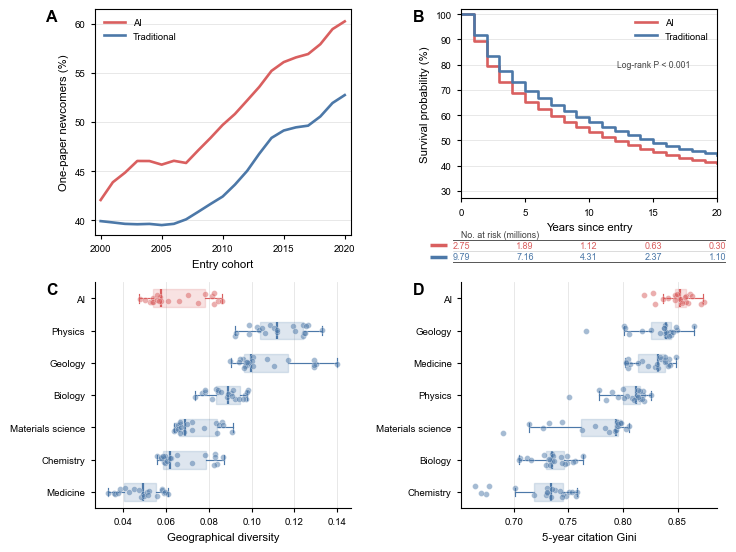

In [4]:
transient = pd.read_csv(FILES['transient']).query('2000 <= cohort <= 2020').copy()
transient['share_ma3'] = transient.groupby('discipline_group')['share'].transform(
    lambda s: s.rolling(3, center=True, min_periods=2).mean()
)
km = pd.read_csv(FILES['km']).query('exit_window == 5 and year <= 20').copy()
country = pd.read_csv(FILES['country']).query('2000 <= year <= 2020').copy()
citation = pd.read_csv(FILES['citation']).query('2000 <= year <= 2020').copy()

fig2 = plt.figure(figsize=(7.25, 5.65))
# Fixed axes positions reproduce the final 2 x 2 layout and preserve the
# approved physical dimensions of the transience and survival panels.
ax_t = fig2.add_axes([0.120000000, 0.583557522, 0.353497164, 0.399982301])
ax_s = fig2.add_axes([0.625500945, 0.648461471, 0.353497164, 0.335078352])
ax_risk = fig2.add_axes([0.625500945, 0.531557522, 0.353497164, 0.049899480])
ax_country = fig2.add_axes([0.120000000, 0.100371681, 0.353497164, 0.399982301])
ax_citation = fig2.add_axes([0.625500945, 0.100371681, 0.353497164, 0.399982301])

# Panel A: one-paper transience
for group in GROUPS:
    z = transient[transient.discipline_group.eq(group)].sort_values('cohort')
    ax_t.plot(z.cohort, 100 * z.share_ma3, color=COLORS[group],
              lw=1.9, label=group, zorder=3)
ax_t.set(xlim=(1999.5, 2020.5), ylim=(38.5, 61.5),
         xlabel='Entry cohort', ylabel='One-paper newcomers (%)')
ax_t.set_xticks([2000, 2005, 2010, 2015, 2020])
ax_t.legend(loc='upper left', handlelength=2.3, borderaxespad=0.55)
style_axis(ax_t, grid='y', boxed=True)
panel_label(ax_t, 'A')

# Panel B: Kaplan–Meier survival
risk_years = [0, 5, 10, 15, 20]
risk_rows = []
for group in GROUPS:
    z = km[km.discipline_group.eq(group)].sort_values('year')
    lower, upper = greenwood_ci(z)
    ax_s.fill_between(z.year, 100 * lower, 100 * upper, step='post',
                      color=COLORS[group], alpha=0.12, linewidth=0)
    ax_s.step(z.year, 100 * z.survival, where='post', color=COLORS[group],
              lw=1.9, label=group)
    risk = z.set_index('year').loc[risk_years, 'at_risk'] / 1_000_000
    risk_rows.append([f'{x:.2f}' for x in risk])

ax_s.set(xlim=(0, 20), ylim=(27, 102), xlabel='Years since entry',
         ylabel='Survival probability (%)')
ax_s.set_xticks(risk_years)
ax_s.legend(loc='upper right', handlelength=2.3, borderaxespad=0.55)
style_axis(ax_s, grid='y', boxed=True)
panel_label(ax_s, 'B')

# Two-sample log-rank test from annual risk sets and event counts
wide_n = km.pivot(index='year', columns='discipline_group', values='at_risk')
wide_d = km.pivot(index='year', columns='discipline_group', values='events')
n1, n2 = wide_n['AI'].astype(float), wide_n['Traditional'].astype(float)
d1, d2 = wide_d['AI'].astype(float), wide_d['Traditional'].astype(float)
nt, dt = n1 + n2, d1 + d2
expected1 = dt * n1 / nt
variance = n1 * n2 * dt * (nt - dt) / (nt.pow(2) * (nt - 1))
valid = (nt > 1) & variance.notna() & (variance > 0)
logrank_chi2 = float((d1[valid].sum() - expected1[valid].sum()) ** 2
                     / variance[valid].sum())
logrank_p = math.erfc(math.sqrt(logrank_chi2 / 2.0))
ax_s.text(15, 80, 'Log-rank P < 0.001', ha='center', va='center',
          fontsize=6.2, color='#454545')

# Number-at-risk table
ax_risk.set_xlim(0, 20)
ax_risk.set_ylim(0, 1)
ax_risk.set_xticks([])
ax_risk.set_yticks([])
for spine in ax_risk.spines.values():
    spine.set_visible(False)
ax_risk.text(0, 0.91, 'No. at risk (millions)', ha='left', va='bottom',
             fontsize=6.4, color='#404040')
for y_rule, color, width in [(0.88, '#555555', 0.7),
                              (0.48, '#C8C8C8', 0.45),
                              (0.08, '#555555', 0.7)]:
    ax_risk.plot([-0.03, 1.03], [y_rule, y_rule], transform=ax_risk.transAxes,
                 color=color, linewidth=width, clip_on=False)
for y, group, values in zip([0.68, 0.28], GROUPS, risk_rows):
    ax_risk.plot([-0.12, -0.055], [y, y], transform=ax_risk.transAxes,
                 color=COLORS[group], lw=2.5, solid_capstyle='butt',
                 clip_on=False)
    for x, value in zip(risk_years, values):
        ax_risk.text(x, y, value, transform=ax_risk.get_xaxis_transform(),
                     ha='center', va='center', fontsize=6.5, color=COLORS[group])

# Panels C and D: annual field distributions
horizontal_field_boxplot(
    ax_country, country, 'mean_paper_country_gini_simpson',
    'Geographical diversity', seed=3107
)
horizontal_field_boxplot(
    ax_citation, citation, 'gini_citations_5y',
    '5-year citation Gini', seed=3108
)
panel_label(ax_country, 'C')
panel_label(ax_citation, 'D')

plt.show()
